# Sesi 8 — HMM-GMM Part 2
Lanjutan Sesi 7: **Audio → STFT → 6 puncak frekuensi → model per kata → prediksi**.

In [26]:
# Hilangkan tanda # jika library belum terpasang, lalu jalankan.
# %pip install numpy==2.2.6 scipy==1.15.3 scikit-learn==1.6.1 matplotlib==3.10.3 hmmlearn==0.3.3 joblib==1.5.1

from pathlib import Path
from math import gcd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from scipy.io import wavfile
from scipy.signal import find_peaks, resample_poly
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from hmmlearn.hmm import GMMHMM

# Mendukung notebook dibuka dari root repo atau code/Sesi8.
ROOT = Path.cwd() if (Path.cwd() / 'code/Sesi7/Audio').is_dir() else Path.cwd().parents[1]
DATA = ROOT / 'code/Sesi7/Audio'
assert DATA.is_dir(), 'Buka notebook dari root repository atau code/Sesi8.'

## 1. Lanjutkan ekstraksi fitur Sesi 7
Tetap gunakan enam puncak STFT. Setiap file kini memiliki panjang sendiri dengan bentuk **(frame, fitur)**. Sample rate disamakan ke 8 kHz. Frame 256 sampel = 32 ms, hop 80 sampel = 10 ms. Enam puncak terkuat diurutkan menurut frekuensi; jika kurang, sisanya diisi nol.

In [27]:
def extract_features(path):
    sr, audio = wavfile.read(path)
    is_uint8 = audio.dtype == np.uint8
    audio = audio.astype(float)
    if is_uint8:
        audio -= 128  # PCM 8-bit memiliki titik nol di 128.
    if audio.ndim == 2:
        audio = audio.mean(axis=1)
    if not audio.size or not np.isfinite(audio).all() or np.max(np.abs(audio)) == 0:
        raise ValueError(f'Audio kosong/hening/tidak valid: {path}')
    factor = gcd(int(sr), 8000)
    audio = resample_poly(audio, 8000 // factor, int(sr) // factor)
    audio = np.pad(audio, (0, max(0, 256 - len(audio))))
    frames = sliding_window_view(audio, 256)[::80]
    spectrum = np.abs(np.fft.rfft(frames * np.hanning(256), axis=1))
    features = np.zeros((len(frames), 6))
    for t, magnitude in enumerate(spectrum):
        peaks, _ = find_peaks(magnitude)
        top = peaks[np.argsort(magnitude[peaks])[-6:]]
        features[t, :len(top)] = np.sort(top) * 8000 / 256
    return features

paths = sorted(DATA.glob('*/*.wav'))
sequences = [extract_features(path) for path in paths]
labels = np.array([path.parent.name for path in paths])
print(f'{len(paths)} rekaman, {len(set(labels))} kata')
print('Bentuk fitur pertama:', sequences[0].shape)

225 rekaman, 14 kata
Bentuk fitur pertama: (36, 6)


## 2. Pisahkan data latih dan uji
Gunakan 75% file untuk training dan 25% untuk testing. `stratify` menjaga keterwakilan kata. Scaler belajar hanya dari frame data latih, lalu dipakai juga pada data uji.

In [28]:
train_idx, test_idx = train_test_split(
    np.arange(len(labels)), test_size=0.25, stratify=labels, random_state=42)
scaler = StandardScaler().fit(np.concatenate([sequences[i] for i in train_idx]))
observations = [scaler.transform(sequence) for sequence in sequences]
print('Latih:', len(train_idx), '| Uji:', len(test_idx))

Latih: 168 | Uji: 57


## 3. Latih satu GMM-HMM per kata
Sesi 7 masih memiliki satu Gaussian per state. Sekarang gunakan **3 state dan 2 Gaussian per state**. EM menghitung posterior state/mixture, lalu memperbarui bobot, mean, varians, dan probabilitas awal/transisi dari seluruh rekaman latih.

`X` menggabungkan frame kata yang sama. **`lengths` menjaga batas rekaman**, sehingga akhir satu file tidak dianggap tersambung ke awal file berikutnya. Regularisasi kovarians membantu menjaga varians positif. State mempelajari pola ucapan, bukan fonem berlabel.

In [29]:
models = {}
for word in sorted(set(labels)):
    selected = [observations[i] for i in train_idx if labels[i] == word]
    X = np.concatenate(selected)
    lengths = [len(sequence) for sequence in selected]
    model = GMMHMM(
        n_components=3, n_mix=2, covariance_type='diag',
        n_iter=30, random_state=42, implementation='log',
        startprob_prior=1.1, transmat_prior=1.1, weights_prior=1.1,
        means_weight=0.01, covars_prior=-1.0, covars_weight=0.01)
    model.fit(X, lengths)
    models[word] = model
    print(f'{word:10s}: {len(selected)} rekaman latih')

apple     : 23 rekaman latih


Model is not converging.  Current: 1384.8368796739908 is not greater than 1384.8471042608894. Delta is -0.01022458689863015


banana    : 11 rekaman latih
book      : 11 rekaman latih
cat       : 11 rekaman latih


Model is not converging.  Current: 1496.378463072869 is not greater than 1496.416485215462. Delta is -0.038022142593035824


dog       : 11 rekaman latih
eye       : 11 rekaman latih
fast      : 11 rekaman latih
god       : 11 rekaman latih
human     : 11 rekaman latih
kiwi      : 11 rekaman latih
lime      : 12 rekaman latih
orange    : 11 rekaman latih
peach     : 12 rekaman latih
pineapple : 11 rekaman latih


## 4. Prediksi dan evaluasi
Hitung `log P(observasi | model kata)` untuk semua kata, lalu pilih skor tertinggi. Ini mengasumsikan prior kata sama. Skor bukan persentase confidence. Pada confusion matrix, **baris = aktual**, **kolom = prediksi**.

Akurasi uji: 85.96%
eye14.wav: aktual=eye, prediksi=apple
eye0.wav: aktual=eye, prediksi=apple
banana09.wav: aktual=banana, prediksi=banana
fast0.wav: aktual=fast, prediksi=fast
orange10.wav: aktual=orange, prediksi=orange


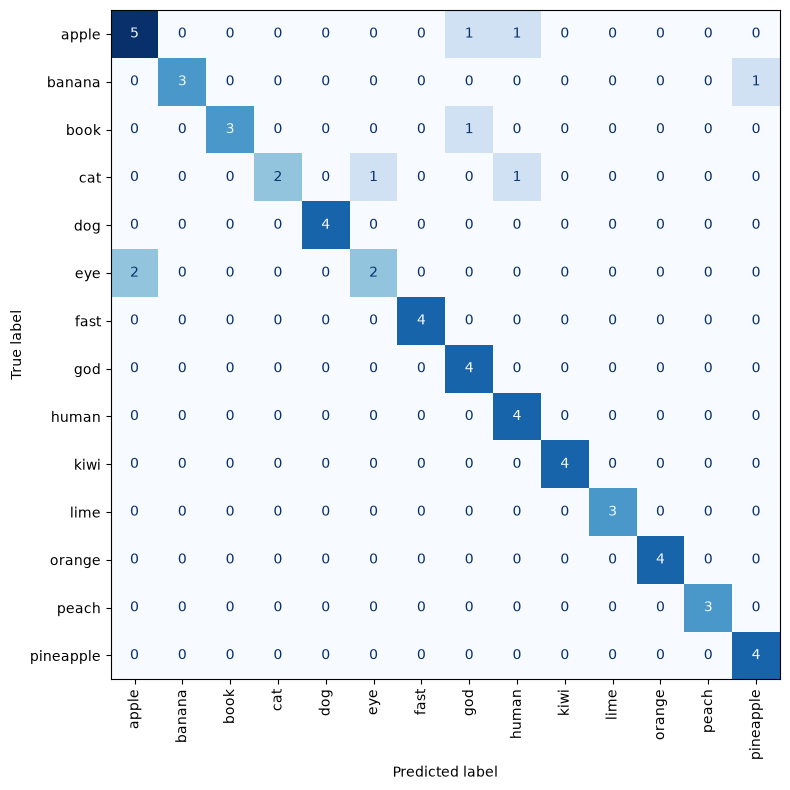

In [30]:
def predict(observation):
    scores = {word: model.score(observation) for word, model in models.items()}
    if not np.isfinite(list(scores.values())).all():
        raise ValueError('Skor model tidak finite; periksa training.')
    return max(scores, key=scores.get)

predictions = [predict(observations[i]) for i in test_idx]
print(f'Akurasi uji: {accuracy_score(labels[test_idx], predictions):.2%}')
for i, prediction in list(zip(test_idx, predictions))[:5]:
    print(f'{paths[i].name}: aktual={labels[i]}, prediksi={prediction}')

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    labels[test_idx], predictions, labels=sorted(models),
    xticks_rotation=90, cmap='Blues', colorbar=False, ax=ax)
plt.tight_layout()
plt.show()

## 5. Simpan dan coba audio lain
Simpan scaler bersama model. Sel ini memuat ulang model dan mencoba satu rekaman uji. Ganti `audio_baru` dengan WAV sendiri berisi salah satu kata yang dilatih. Muat hanya file joblib yang Anda buat atau percayai.

In [31]:
model_path = ROOT / 'code/Sesi8/model_sesi8.joblib'
joblib.dump({'models': models, 'scaler': scaler}, model_path)
saved = joblib.load(model_path)

audio_baru = paths[test_idx[55]]  # Ganti dengan Path('lokasi/rekaman_baru.wav').
features = saved['scaler'].transform(extract_features(audio_baru))
scores = {word: model.score(features) for word, model in saved['models'].items()}
print('File:', audio_baru.name)
print('Prediksi:', max(scores, key=scores.get))

File: lime11.wav
Prediksi: lime
